In [1]:
!pip install librosa

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 473.0/473.0 kB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 118.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 89.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.4/240.4 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 60.7 MB/s eta 0:00:00:00:0100:01


In [2]:
# lets plot the audio waveform using librosa standard audio within library
import librosa

array, sampling_rate = librosa.load(librosa.ex("trumpet"))

In [4]:
print(array, sampling_rate)

[-1.4068222e-03 -4.4607258e-04 -4.1098078e-04 ...  7.9623051e-06
 -3.0417003e-05  1.2765067e-05] 22050


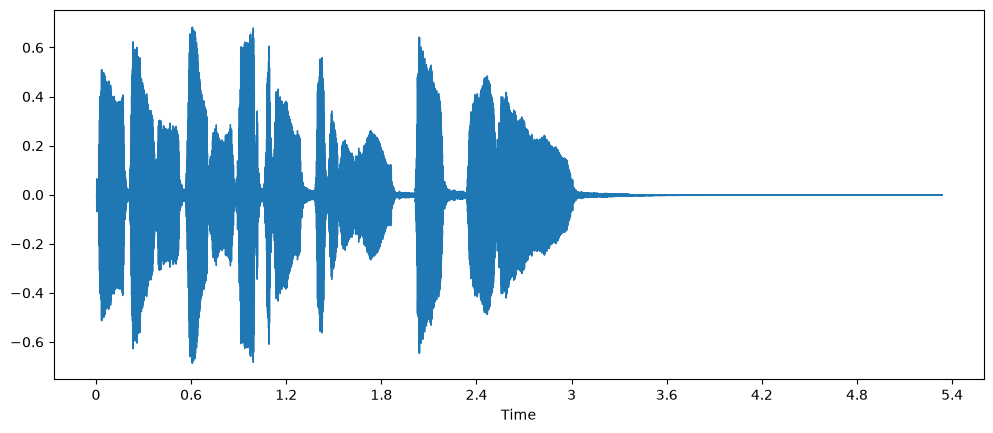

In [3]:
import matplotlib.pyplot as plt
import librosa.display

plt.figure().set_figwidth(12)
librosa.display.waveshow(array, sr=sampling_rate)

In [5]:
# Another way to visualize audio data is to plot the frequency spectrum of an audio signal, also known as the frequency domain representation. The spectrum is computed using the discrete Fourier transform or DFT. It describes the individual frequencies that make up the signal and how strong they are.

# Let’s plot the frequency spectrum for the same trumpet sound by taking the DFT using numpy’s rfft() function. 

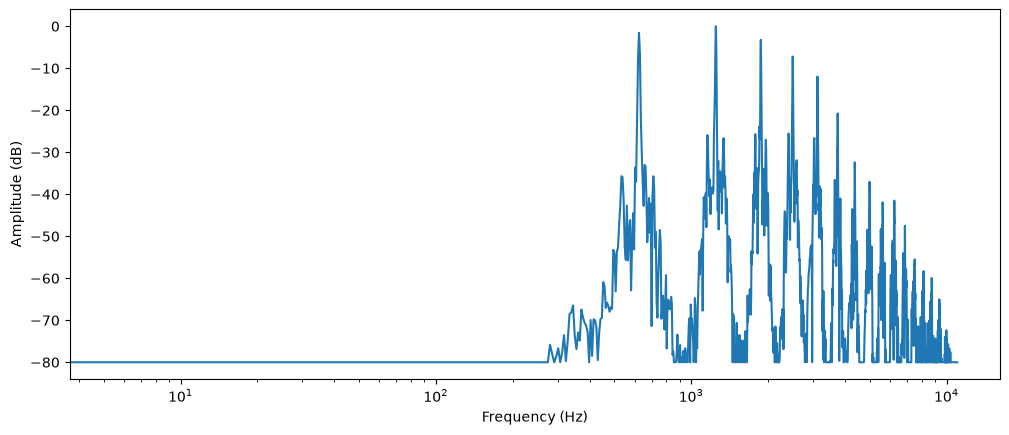

In [6]:
import numpy as np

dft_input = array[:4096]

# calculate the DFT
window = np.hanning(len(dft_input))
windowed_input = dft_input * window
dft = np.fft.rfft(windowed_input)

# get the amplitude spectrum in decibels
amplitude = np.abs(dft)
amplitude_db = librosa.amplitude_to_db(amplitude, ref=np.max)

# get the frequency bins
frequency = librosa.fft_frequencies(sr=sampling_rate, n_fft=len(dft_input))

plt.figure().set_figwidth(12)
plt.plot(frequency, amplitude_db)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (dB)")
plt.xscale("log")

In [7]:
# A spectrogram plots the frequency content of an audio signal as it changes over time. It allows you to see time, frequency, and amplitude all on one graph. The algorithm that performs this computation is the STFT or Short Time Fourier Transform.

# The spectrogram is one of the most informative audio tools available to you. For example, when working with a music recording, you can see the various instruments and vocal tracks and how they contribute to the overall sound. In speech, you can identify different vowel sounds as each vowel is characterized by particular frequencies.

# Let’s plot a spectrogram for the same trumpet sound, using librosa’s stft() and specshow() functions:

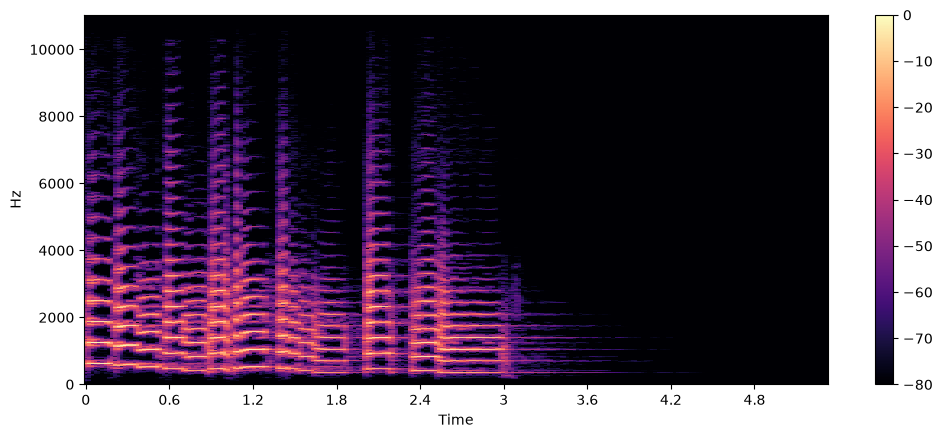

In [8]:
import numpy as np

D = librosa.stft(array)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure().set_figwidth(12)
librosa.display.specshow(S_db, x_axis="time", y_axis="hz")
plt.colorbar()

A mel spectrogram is a variation of the spectrogram that is commonly used in speech processing and machine learning tasks. It is similar to a spectrogram in that it shows the frequency content of an audio signal over time, but on a different frequency axis.

In a standard spectrogram, the frequency axis is linear and is measured in hertz (Hz). However, the human auditory system is more sensitive to changes in lower frequencies than higher frequencies, and this sensitivity decreases logarithmically as frequency increases. The mel scale is a perceptual scale that approximates the non-linear frequency response of the human ear.

To create a mel spectrogram, the STFT is used just like before, splitting the audio into short segments to obtain a sequence of frequency spectra. Additionally, each spectrum is sent through a set of filters, the so-called mel filterbank, to transform the frequencies to the mel scale.

Let’s see how we can plot a mel spectrogram using librosa’s melspectrogram() function, which performs all of those steps for us:

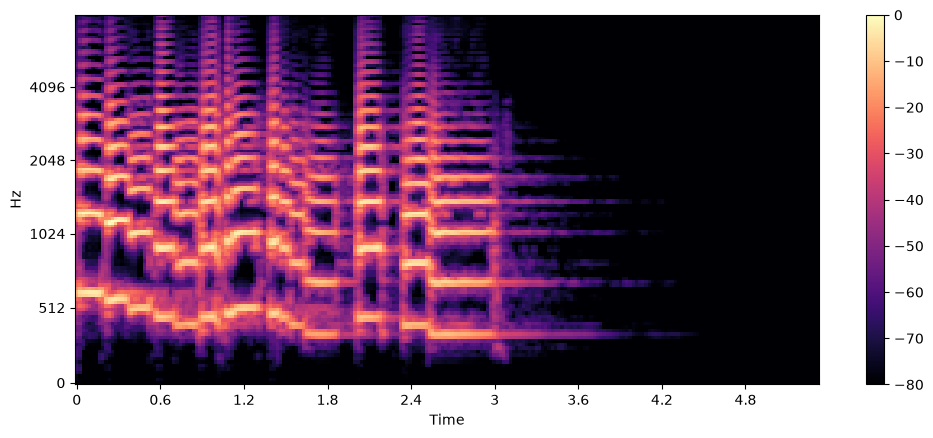

In [9]:
S = librosa.feature.melspectrogram(y=array, sr=sampling_rate, n_mels=128, fmax=8000)
S_dB = librosa.power_to_db(S, ref=np.max)

plt.figure().set_figwidth(12)
librosa.display.specshow(S_dB, x_axis="time", y_axis="mel", sr=sampling_rate, fmax=8000)
plt.colorbar()

In [13]:
# Load and explore audio data, Let’s load and explore and audio dataset called MINDS-14, which contains recordings of people asking an e-banking system questions in several languages and dialects.

In [16]:
!pip install datasets[audio] soundfile librosa torchcodec ffmpeg

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for ffmpeg: filename=ffmpeg-1.4-py3-none-any.whl size=6126 sha256=bd735b8bcb07beeacc458c393d0f17254eec0b9a8c2708f3fae80ee4a6c38514
  Stored in directory: /home/ubuntu/.cache/pip/wheels/26/21/0c/c26e09dff860a9071683e279445262346e008a9a1d2142c4ad
Successfully built ffmpeg


In [2]:
from datasets import load_dataset

minds = load_dataset("PolyAI/minds14", name="en-AU", split="train")
minds

Dataset({
    features: ['path', 'audio', 'transcription', 'english_transcription', 'intent_class', 'lang_id'],
    num_rows: 654
})

In [3]:
example = minds[0]
example

{'path': 'en-AU~PAY_BILL/response_4.wav',
 'audio': <datasets.features._torchcodec.AudioDecoder at 0x7e78c35b6ff0>,
 'transcription': 'I would like to pay my electricity bill using my card can you please assist',
 'english_transcription': 'I would like to pay my electricity bill using my card can you please assist',
 'intent_class': 13,
 'lang_id': 2}

In [1]:
!sudo apt update && sudo apt install -y ffmpeg

Hit:1 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble InRelease
Get:2 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:3 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:4 https://nvidia.github.io/libnvidia-container/stable/deb/amd64  InRelease [1477 B]m
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]      
Get:6 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble-updates/main amd64 Packages [1400 kB]
Get:7 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble-updates/main Translation-en [309 kB]
Get:8 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble-updates/main amd64 Components [181 kB]
Get:9 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [1706 kB]
Get:10 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble-updates/universe Translation-en [342 kB]
Get:11 http://us-east-1.ec2.archive.ubuntu.com/ubuntu noble-updates/universe amd64 Components [

In [7]:
example = minds[100]
example

{'path': 'en-AU~APP_ERROR/response_28.wav',
 'audio': <datasets.features._torchcodec.AudioDecoder at 0x7e77e0186480>,
 'transcription': "I'm trying to use the new app but the app does not load it keeps freezing",
 'english_transcription': "I'm trying to use the new app but the app does not load it keeps freezing",
 'intent_class': 2,
 'lang_id': 2}

In [8]:
id2label = minds.features["intent_class"].int2str
id2label(example["intent_class"])

'app_error'

In [9]:
example["intent_class"]

2

In [10]:
id2label

<bound method ClassLabel.int2str of ClassLabel(names=['abroad', 'address', 'app_error', 'atm_limit', 'balance', 'business_loan', 'card_issues', 'cash_deposit', 'direct_debit', 'freeze', 'high_value_payment', 'joint_account', 'latest_transactions', 'pay_bill'])>

In [11]:
minds.shape

(654, 6)

In [14]:
# load audio sample on the fly
audio_input = minds[0]["audio"]  # first decoded audio sample
intent_class = minds[0]["intent_class"]  # first transcription
intent = minds.features["intent_class"].names[intent_class]

In [15]:
print(audio_input)

In [16]:
print(intent_class)

13


In [17]:
print(intent)

pay_bill


In [18]:
columns_to_remove = ["lang_id", "english_transcription"]
minds = minds.remove_columns(columns_to_remove)
minds

Dataset({
    features: ['path', 'audio', 'transcription', 'intent_class'],
    num_rows: 654
})

In [41]:
!pip install gradio transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 127.8 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 61.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 131.8 MB/s eta 0:00:00


In [23]:
# import gradio as gr


# def generate_audio():
#     example = minds.shuffle()[0]
#     audio = example["audio"]
#     return (
#         audio["sampling_rate"],
#         audio["array"],
#     ), id2label(example["intent_class"])


# with gr.Blocks() as demo:
#     with gr.Column():
#         for _ in range(4):
#             audio, label = generate_audio()
#             output = gr.Audio(audio, label=label)

# demo.launch(debug=True, share=True)

In [25]:
from IPython.display import Audio, display

for i in range(3):
    s = minds[i]["audio"].get_all_samples()
    print(s.sample_rate)
    print(minds[i]["transcription"])
    display(Audio(s.data.numpy(), rate=s.sample_rate))

8000
I would like to pay my electricity bill using my card can you please assist


8000
hello I like to pay for Bill I would actually like to make a payment but yeah could you help me


8000
pay a bill


In [28]:
# Preprocess the audio dataset 
#  Most of the available pretrained models have been pretrained on audio datasets at a sampling rate of 16 kHz. 
# When we explored MINDS-14 dataset, you may have noticed that it is sampled at 8 kHz, which means we will likely need to upsample it.

# To do so, use 🤗 Datasets’ cast_column method. This operation does not change the audio in-place, but rather signals to datasets to 
#resample the audio examples on the fly when they are loaded. The following code will set the sampling rate to 16kHz:


In [27]:
from datasets import Audio

minds = minds.cast_column("audio", Audio(sampling_rate=16_000))

In [29]:
# What HF's Audio class actually does, decomposed:

#     Phase 1 - Lazy abstraction
#         `dataset.cast_column("audio", Audio(sampling_rate=16000))` touches
#         no audio bytes. It records in the column's schema metadata that
#         rows of this column should be *interpreted* as audio and
#         delivered at 16 kHz. On disk the rows are still `{"path": str}`
#         or `{"bytes": b"..."}` structs.

#     Phase 2 - Decode-on-index
#         `dataset[i]["audio"]` is the first point work happens. The
#         feature's `decode_example` is called: read bytes/path -> decode
#         to a float waveform at the file's native rate `fs_old` ->
#         resample to the target `fs_new` if they differ.

#     Phase 3 - The resample itself
#         HF forwards the float array to `librosa.resample` with
#         `res_type="soxr_hq"` (its current default). librosa delegates to
#         `soxr`, which performs band-limited Kaiser-windowed sinc
#         interpolation in compiled C: a polyphase bank of sinc kernels,
#         with a low-pass cutoff at min(fs_old, fs_new)/2 as the
#         anti-aliasing filter, Kaiser-windowed to control stopband
#         ripple.

In [30]:
minds[0]


{'path': 'en-AU~PAY_BILL/response_4.wav',
 'audio': <datasets.features._torchcodec.AudioDecoder at 0x7e78dc3603e0>,
 'transcription': 'I would like to pay my electricity bill using my card can you please assist',
 'intent_class': 13}

In [33]:
from IPython.display import Audio, display

s = minds[0]["audio"].get_all_samples()
print(s.sample_rate)
print(minds[0]["transcription"])
display(Audio(s.data.numpy(), rate=s.sample_rate))

16000
I would like to pay my electricity bill using my card can you please assist


In [34]:
# One of the common cases involves limiting the audio examples to a certain duration. 
# For instance, we might want to filter out any examples longer than 20s to prevent out-of-memory errors when training a model.

# We can do this by using the 🤗 Datasets’ filter method and passing a function with filtering logic to it. 
# Let’s start by writing a function that indicates which examples to keep and which to discard. 
# This function, is_audio_length_in_range, returns True if a sample is shorter than 20s, and False if it is longer than 20s.

In [36]:
import librosa

MAX_DURATION_IN_SECONDS = 20.0


def is_audio_length_in_range(input_length):
    return input_length < MAX_DURATION_IN_SECONDS


# use librosa to get example's duration from the audio file
new_column = [
    librosa.get_duration(y=x["array"], sr=x["sampling_rate"]) for x in minds["audio"]
]
minds = minds.add_column("duration", new_column)

# use 🤗 Datasets' `filter` method to apply the filtering function
minds = minds.filter(is_audio_length_in_range, input_columns=["duration"])

# remove the temporary helper column
minds = minds.remove_columns(["duration"])
minds

Filter:   0%|          | 0/654 [00:00<?, ? examples/s]

Dataset({
    features: ['path', 'audio', 'transcription', 'intent_class'],
    num_rows: 624
})

In [39]:
# the most challenging aspects of working with audio datasets is preparing the data in the right format for model training. As you saw, the 
# raw audio data comes as an array of sample values. However, pre-trained models, whether you use them for inference, 
# or want to fine-tune them for your task, expect the raw data to be converted into input features. 
# The requirements for the input features may vary from one model to another — they depend on the model’s architecture, and the data it 
# was pre-trained with. The good news is, for every supported audio model, 
# 🤗 Transformers offer a feature extractor class that can convert raw audio data into the input features the model expects.

In [38]:
# So what does a feature extractor do with the raw audio data? Let’s take a look at Whisper’s feature extractor to understand some common
# feature extraction transformations. 

In [42]:
from transformers import WhisperFeatureExtractor

feature_extractor = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

In [43]:
def prepare_dataset(example):
    audio = example["audio"]

    if audio["sampling_rate"] != 16000:
        audio_array = librosa.resample(
            audio["array"], orig_sr=audio["sampling_rate"], target_sr=16000
        )
        audio = {"array": audio_array, "sampling_rate": 16000}

    features = feature_extractor(
        audio["array"], sampling_rate=audio["sampling_rate"], padding=True
    )
    return features